# Lab 2
# Parametric regression
# ---------------------------------------------------

<h2>Table of Contents</h2>

<div class="alert alert-block alert-info" style="margin-top: 20px">
<ol>
    <li> Introduction </li>
    <li> Cross Validation </li>
    <li> Simple Linear Regression </li>
    <li> Multiple Linear Regression </li>
    <li> Non-Linear Regression </li>
    <li> Linear Regression with Regularization </li>
    <li> Comparison of the results obtained with the different models </li>
</ol>
</div>

<hr>

## 1. Introduction

Suppose you want to build a parametric regression model on a set of cases, where each case is described in terms of several variables. Without knowing anything else about the data set, give a reasoned justification:

a) Explain in your own words what is the main difference between supervised and unsupervised learning methods. Give an example of the application of each type of method. Describe briefly the input and output variables you would consider in each example.

b) Explain in your own words the main difference between a linear and a non-linear model.

c) Explain the concept of overfitting and generalization. If you wish, you can support your answer with an outline or drawing. Explain in your own words how you could get the designed model to generalize well.

**a) Supervised vs. unsupervised.** In **supervised** learning every training case has a known output (a label or target value), and the model learns the mapping input → output so it can predict the output of new cases; its error can be measured directly by comparing predictions with the true outputs. In **unsupervised** learning there is no output variable: the algorithm only receives inputs and looks for structure in them (groups, patterns, a lower-dimensional representation).

* *Supervised example (this lab):* predict the plasma **glucose** of a patient (output, continuous → regression) from inputs such as age, BMI, insulin, blood pressure, skin thickness, number of pregnancies and diabetes pedigree function. If the output were *diabetic / non-diabetic* it would be a classification problem (Lab 3).
* *Unsupervised example:* **clustering** patients with K-means using the same clinical measurements (inputs) to discover phenotypes or risk profiles. There is no output variable: the result is a cluster assignment for each patient that we must interpret afterwards. Another example: PCA to reduce the dimensionality of gene-expression data.

**b) Linear vs. non-linear model.** A model is **linear** when the output is a weighted sum of the inputs, $\hat y = w_0 + w_1x_1 + \dots + w_dx_d$: the effect of each variable is constant (one unit more of $x_j$ always changes $\hat y$ by $w_j$) and the model is a straight line / plane / hyperplane. A **non-linear** model can represent curves, interactions and thresholds: the effect of a variable depends on its own value or on other variables (e.g. $\hat y = w_0 + w_1x + w_2x^2$, $\hat y = a\,e^{bx}$, a neural network). Non-linear models are more flexible but have more parameters and a greater risk of overfitting. (Note: a polynomial regression is non-linear in $x$ but still *linear in the parameters*, which is why it can be fitted with ordinary least squares on the expanded features.)

**c) Overfitting and generalization.** **Generalization** is the ability of a model to perform well on *new* data that it did not see during training, which is what we really care about. **Overfitting** occurs when the model is too complex for the amount of data: it learns not only the real pattern but also the noise of the training set (it "memorises" it). Its training error is very low but the error on new data is high. The opposite, **underfitting**, is a model too simple to capture the pattern (high error everywhere).

```
error
  |\                                  validation error
  | \                              __/
  |  \___                     ___/
  |      \______       ______/
  |             \_____/          <- best complexity
  |  \_______
  |          \_________________   training error
  +------------------------------------> model complexity
     underfitting        overfitting
```

To make the model generalize well: keep a separate **test set** never used for training; choose the model complexity / hyper-parameters with **cross-validation** (look where the validation error is minimum, not the training error); use **regularization** (Ridge, Lasso), **feature selection** and simpler models; get **more data**; and avoid information leakage (fit scalers/imputers only on the training data).

For the development of this second lab, the database "Pima Indian Diabetes" already pre-processed will be analyzed, where the rows of the file correspond to the cases and the columns to the variables. Important, you should use the preprocessed dataset.

For this practice, the data will be divided into two subsets: training and test. In addition, the validation scheme called k-fold cross validation will be considered.

#### Note that in this data, the goal is to predict, based on diagnostic measurements, whether a patient has diabetes. However, in this lab, we will deal with a regression task, this is, we will change the output

## 2. Cross-validation

For this practice, the validation scheme called k-fold cross validation will be considered. Remember that in this approach, the available cases are randomly divided into k subsets of the same size called "folds".

a) Indicate what a k-fold cross-validation scheme can be used for.

b) Justify reasonably which models will need to follow a cross-validation scheme.

c) As discussed in the theoretical classes, it is common in health to have a different number of cases in each class (unbalanced classes). Taking into account the database of this practice, please explain in detail the figure of merit you would consider in order to analyze the results with different parametric schemes.

**a) What k-fold CV is used for.** The training set is split into k folds; the model is trained k times, each time on k−1 folds and validated on the remaining fold, and the k validation scores are averaged. It is used to:
1. **Estimate the generalization performance** of a model without touching the test set, using every training case once for validation (more reliable than a single validation split, and we also get its variability: mean ± std).
2. **Select hyper-parameters / model complexity** (polynomial degree, regularization strength α, number of features): we choose the value with the best mean validation score.
3. **Compare different models** fairly and detect overfitting (a large gap between training and validation scores).

Once the hyper-parameters are chosen, the model is retrained on the whole training set and evaluated only once on the test set.

**b) Which models need it.** Any model with **hyper-parameters that are not learned by the fitting itself** needs CV to tune them: polynomial regression (degree), Ridge and Lasso (α), and also any feature-selection step (how many / which variables). Ordinary simple and multiple linear regression have no hyper-parameters (the coefficients have a closed-form least-squares solution), so they do not *need* CV to be fitted; however, we still use CV for them to estimate their validation performance and compare them with the rest of models on equal terms.

**c) Figure of merit.** In this lab the output (Glucose) is continuous, so we evaluate with regression metrics on the **test set** (and their CV equivalents):
* **MAE** $=\frac1n\sum|y_i-\hat y_i|$: average error in mg/dl, easy to interpret clinically and robust to outliers.
* **MSE** $=\frac1n\sum(y_i-\hat y_i)^2$: penalises large errors much more (it is the quantity least squares minimises), but its units are (mg/dl)².
* **RMSE** $=\sqrt{\text{MSE}}$: same units as glucose → my **main figure of merit**, since large errors (e.g. missing a hyperglycaemic patient) are clinically the most dangerous.
* **R²** $= 1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$: fraction of the variance of glucose explained by the model (1 = perfect, 0 = as good as always predicting the mean, < 0 = worse than the mean). It is useful to compare models because it does not depend on units.

**About class imbalance:** 65 % of patients are non-diabetic, so most glucose values are normal. A regression model is pulled towards the majority and tends to **underestimate high glucose values of diabetic patients** (precisely the clinically relevant ones), while the global RMSE/R² can hide this because it is dominated by the majority. Therefore, besides the global metrics, it is advisable to (1) analyse the error **separately for diabetic and non-diabetic patients** (done in Section 7) and the residual plots, and (2) use splits/folds that preserve the class proportions (**stratified** by Outcome). If the problem were classification (Lab 3), accuracy would be misleading (65 % by always saying "healthy"), and we would use **sensitivity, specificity, balanced accuracy, F1 and ROC-AUC** together with the confusion matrix.

In [4]:
from sklearn.model_selection import cross_val_score
from sklearn import model_selection
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn import metrics
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib
from matplotlib import pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [5]:
# Load data from csv and store it in dataframe (the preprocessed one, created at the end of Lab 1:
# impossible zeros of Glucose, BloodPressure, SkinThickness, Insulin and BMI replaced by the mean of the valid values)
data = pd.read_csv("/home/alumnos/cesarrbl/Escritorio/CUARTO/AI AND LEARNING/LABS-AI-and-LEARNING/LAB1/Lab1_Material/pima_preprocessed.csv")

# Show the first rows
print(data.shape)
display(data.head())

# Define the input and output data
# Glucose is the dependent variable in this lab.
# Outcome is NOT used as input: the diagnosis of diabetes is made precisely from the glucose test,
# so using it to predict glucose would be information leakage (and it would not be known before measuring glucose).
X = data.drop(columns=['Glucose', 'Outcome'])
Y = data['Glucose']

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


In [6]:
# Show the first rows of the input data
X.head()

,Pregnancies,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,72.0,35.00000,155.548223,33.6,0.627,50
1,1,66.0,29.00000,155.548223,26.6,0.351,31
2,8,64.0,29.15342,155.548223,23.3,0.672,32
3,1,66.0,23.00000,94.000000,28.1,0.167,21
4,0,40.0,35.00000,168.000000,43.1,2.288,33


In [7]:
# Show the first rows of the output data
Y.head()

0    148.0
1     85.0
2    183.0
3     89.0
4    137.0
Name: Glucose, dtype: float64

In [8]:
# Define the Train (70% of the samples) and Test sets (30% of the samples) - tip: train_test_split
# Please, use the option random state to obtain always the same results
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)
print("X_train:", X_train.shape, " X_test:", X_test.shape, " Y_train:", Y_train.shape, " Y_test:", Y_test.shape)

X_train: (537, 7)  X_test: (231, 7)  Y_train: (537,)  Y_test: (231,)


In [9]:
# Show the first rows of X_train
X_train.head()

,Pregnancies,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
334,1,60.0,18.0,58.0,23.9,0.260,22
139,5,72.0,29.0,325.0,36.9,0.159,28
485,0,68.0,42.0,250.0,42.3,0.365,24
547,4,68.0,21.0,166.0,33.1,0.160,28
18,1,30.0,38.0,83.0,43.3,0.183,33


#### Define variables for the following figure of merits: R^2, MAE, MSE and RMSE

In [10]:
# Lists to store the results of every model (test set) and the cross-validation results (validation)
model_names = []
r2_results, mae_results, mse_results, rmse_results = [], [], [], []
cv_r2_results, cv_rmse_results, cv_train_r2_results = [], [], []

# 5-fold cross-validation on the TRAINING set (shuffled, fixed seed -> reproducible)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

def regression_metrics(y_true, y_pred):
    """Return R2, MAE, MSE and RMSE."""
    mse = metrics.mean_squared_error(y_true, y_pred)
    return (metrics.r2_score(y_true, y_pred), metrics.mean_absolute_error(y_true, y_pred), mse, np.sqrt(mse))

def evaluate(name, model, Xtr, Xte, ytr=None, yte=None, verbose=True):
    """Cross-validate `model` on the training set, fit it on the whole training set,
    evaluate it on the test set and store everything in the result lists."""
    ytr = Y_train if ytr is None else ytr
    yte = Y_test if yte is None else yte
    cv = model_selection.cross_validate(model, Xtr, ytr, cv=kfold,
                                        scoring=['r2', 'neg_root_mean_squared_error'], return_train_score=True)
    model.fit(Xtr, ytr)
    r2, mae, mse, rmse = regression_metrics(yte, model.predict(Xte))
    model_names.append(name)
    r2_results.append(r2); mae_results.append(mae); mse_results.append(mse); rmse_results.append(rmse)
    cv_r2_results.append(cv['test_r2'].mean()); cv_train_r2_results.append(cv['train_r2'].mean())
    cv_rmse_results.append(-cv['test_neg_root_mean_squared_error'].mean())
    if verbose:
        print(f"{name}\n  CV (validation): R2 = {cv['test_r2'].mean():.4f} ± {cv['test_r2'].std():.4f} | "
              f"RMSE = {-cv['test_neg_root_mean_squared_error'].mean():.2f}"
              f"\n  Test:            R2 = {r2:.4f} | MAE = {mae:.2f} | MSE = {mse:.2f} | RMSE = {rmse:.2f}")
    return model

## 3. Simple Linear Regression

Linear regression allows us to establish the relationship between the input and the output. This technique is used when the relationship between the variables is linear.

Indicate:

a) What is the output (dependent) variable that you could consider to address a linear regression problem?

b) Indicate whether the performance obtained in the test set change after normalizing the variables.

In [11]:
from sklearn import model_selection
from sklearn import metrics
from sklearn.linear_model import LinearRegression

# Simple linear regression - Tip: LinearRegression()
regressor = LinearRegression()

# Train the model using the training set, consider the feature 'Age' as the input and the output
regressor.fit(X_train[['Age']], Y_train)

# Show the intercept
print("Intercept (w0):", regressor.intercept_)

# Show the coefficients
print("Coefficient (w1, Age):", regressor.coef_)

# Predict using the test set
y_pred = regressor.predict(X_test[['Age']])

# Compute R2, MAE, MSE and RMSE
r_squared = metrics.r2_score(Y_test, y_pred)
mae = metrics.mean_absolute_error(Y_test, y_pred)
mse = metrics.mean_squared_error(Y_test, y_pred)
rmse = np.sqrt(mse)

print(f'R Squared: {r_squared} \n Mean Absolute Error: {mae} \n Mean Squared Error: {mse} \n Root Mean Squared Error: {rmse}')

Intercept (w0): 98.681688688394
Coefficient (w1, Age): [0.7044855]
R Squared: 0.061933586486173864 
 Mean Absolute Error: 25.06204026012269 
 Mean Squared Error: 907.5609810535843 
 Root Mean Squared Error: 30.12575278816422


In [12]:
# Store the results (and the cross-validation estimate) of this model
_ = evaluate("Linear Regression (LR) - Age", LinearRegression(), X_train[['Age']], X_test[['Age']])

Linear Regression (LR) - Age
  CV (validation): R2 = 0.0513 ± 0.0528 | RMSE = 29.16
  Test:            R2 = 0.0619 | MAE = 25.06 | MSE = 907.56 | RMSE = 30.13


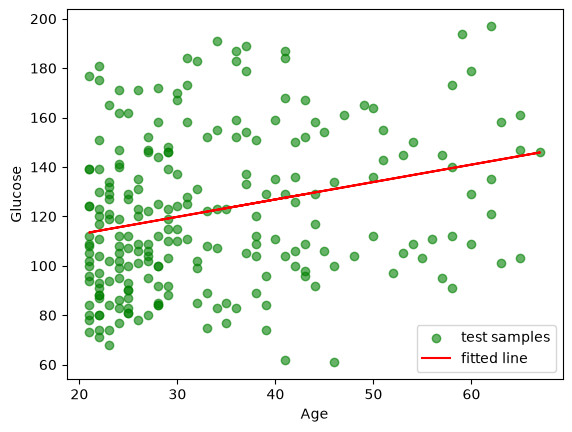

In [13]:
# Plot the samples and the prediction
plt.scatter(X_test['Age'], Y_test, color='g', alpha=0.6, label='test samples')
plt.plot(X_test['Age'], y_pred, color='r', label='fitted line')
plt.xlabel('Age')
plt.ylabel("Glucose")
plt.legend()
plt.show()

The fitted model is $\widehat{Glucose} = 98.68 + 0.70\cdot Age$: each additional year of age increases the predicted glucose by ≈0.7 mg/dl. The relationship is positive but **very weak**: R² ≈ 0.06 (Age explains only 6 % of the variance of glucose) and the typical error is RMSE ≈ 30 mg/dl, almost as large as the standard deviation of glucose itself (≈30 mg/dl). The scatter plot confirms it: for any age the glucose values are spread over a huge range around the line.

In [14]:
# Which single feature is the best predictor? (simple LR with each feature, 5-fold CV on the training set)
single = {}
for col in X.columns:
    single[col] = cross_val_score(LinearRegression(), X_train[[col]], Y_train, cv=kfold, scoring='r2').mean()
pd.Series(single, name='CV R2 (simple LR)').sort_values(ascending=False).round(4)

Insulin                     0.1592
Age                         0.0513
BMI                         0.0434
BloodPressure               0.0265
DiabetesPedigreeFunction    0.0192
Pregnancies                 0.0060
SkinThickness               0.0036
Name: CV R2 (simple LR), dtype: float64

Age is not the best single predictor: **Insulin** explains the most variance of glucose (CV R² ≈ 0.16), coherent with physiology (insulin and glucose are regulated together and both are measured in the oral glucose tolerance test). The rest of variables explain about 5 % or less each on their own.

In [15]:
# Normalize using StandardScaler() - Important, note that you have two sets train and test
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

scaler = StandardScaler()
X_train_std = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)  # fit ONLY with train
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)         # same mean/std on test

# Build a simple linear regression model and show the prediction results in the test sets based on R2, MAE, MSE and RMSE
regressor_std = LinearRegression().fit(X_train_std[['Age']], Y_train)
print("Intercept:", regressor_std.intercept_, "| Coefficient:", regressor_std.coef_)
y_pred_std = regressor_std.predict(X_test_std[['Age']])
r2, mae, mse, rmse = regression_metrics(Y_test, y_pred_std)
print(f'R Squared: {r2} \n Mean Absolute Error: {mae} \n Mean Squared Error: {mse} \n Root Mean Squared Error: {rmse}')
print("Max difference between predictions without/with normalization:", np.abs(y_pred - y_pred_std).max())

# Store it. The scaler goes inside a pipeline so that, in cross-validation, it is fitted only on the training folds
_ = evaluate("LR Normalized - Age", make_pipeline(StandardScaler(), LinearRegression()), X_train[['Age']], X_test[['Age']], verbose=False)

Intercept: 121.98218587317047 | Coefficient: [8.22446931]
R Squared: 0.061933586486173864 
 Mean Absolute Error: 25.06204026012269 
 Mean Squared Error: 907.5609810535843 
 Root Mean Squared Error: 30.12575278816422
Max difference between predictions without/with normalization: 2.842170943040401e-14


**a) Output variable.** For a linear regression problem the output must be a **continuous numerical** variable. In this dataset the natural choice is **Glucose** (as indicated in the lab): it is the key variable in the diagnosis of diabetes and it is continuous. Other numerical variables (BMI, BloodPressure, Insulin) could also be used as outputs, but `Outcome` cannot: it is binary, so it is a classification problem (logistic regression, Lab 3).

**b) Effect of normalization.** **The performance on the test set does not change at all** (R², MAE, MSE and RMSE are identical, and the predictions differ only by ~1e-14, rounding error). What changes are the **parameters**: after standardization the intercept becomes the mean glucose of the training set (121.98) and the coefficient becomes the change in glucose per **one standard deviation** of Age (≈8.2 mg/dl per 11.8 years) instead of per year (0.70). This happens because standardization is an affine transformation $x' = (x-\mu)/\sigma$, and ordinary least squares simply absorbs it into the parameters: $w_1' = w_1\sigma$, $w_0' = w_0 + w_1\mu$. The fitted line is exactly the same. (Normalization *does* matter for regularized models — Ridge, Lasso — and for numerical stability, as we will see.)

## 4. Multiple Linear Regression

In this section we will analyze:

a) How the value of the estimators, the correlation coefficient and the figure of merit change when we change the number of explanatory variables.

b) The most relevant features. Explain in detail the process you have followed and justify which features are most relevant in this database.

Note: you may have to repeat this section with a different number of variables in order to draw valid conclusions.

In [16]:
# Build a multiple linear regression model (all 7 normalized features) and show the prediction results in the test set based on R2, MAE, MSE and RMSE
mlr = LinearRegression().fit(X_train_std, Y_train)
y_pred_mlr = mlr.predict(X_test_std)
r2, mae, mse, rmse = regression_metrics(Y_test, y_pred_mlr)
print(f'R Squared: {r2:.4f} | MAE: {mae:.2f} | MSE: {mse:.2f} | RMSE: {rmse:.2f}')

# Without normalization the predictions are the same (only the coefficients change)
mlr_raw = LinearRegression().fit(X_train, Y_train)
print("Test R2 without normalization:", round(metrics.r2_score(Y_test, mlr_raw.predict(X_test)), 4))

_ = evaluate("Multiple LR Normalized", make_pipeline(StandardScaler(), LinearRegression()), X_train, X_test)

R Squared: 0.2110 | MAE: 22.13 | MSE: 763.31 | RMSE: 27.63
Test R2 without normalization: 0.211
Multiple LR Normalized
  CV (validation): R2 = 0.2355 ± 0.0461 | RMSE = 26.16
  Test:            R2 = 0.2110 | MAE = 22.13 | MSE = 763.31 | RMSE = 27.63


Intercept (normalized): 121.982 | Intercept (original units): 45.682


,coef (normalized X),coef (original units)
Pregnancies,0.0111,0.0034
BloodPressure,2.9436,0.2414
SkinThickness,-2.1315,-0.2517
Insulin,10.7020,0.1260
BMI,5.6985,0.8190
DiabetesPedigreeFunction,3.1217,9.1340
Age,5.5722,0.4773


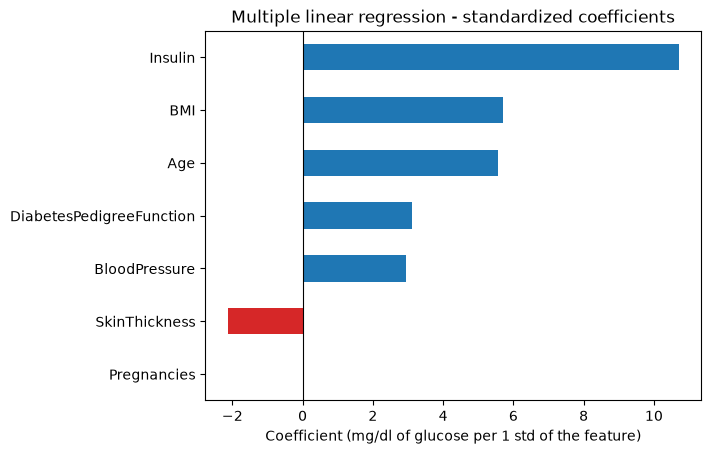

In [17]:
# Show and plot the values of the coefficients. Comment the results
coefs = pd.DataFrame({'coef (normalized X)': mlr.coef_, 'coef (original units)': mlr_raw.coef_}, index=X.columns)
print("Intercept (normalized):", round(mlr.intercept_, 3), "| Intercept (original units):", round(mlr_raw.intercept_, 3))
display(coefs.round(4))

order = coefs['coef (normalized X)'].abs().sort_values().index
coefs.loc[order, 'coef (normalized X)'].plot(kind='barh', color=['tab:red' if v < 0 else 'tab:blue' for v in coefs.loc[order, 'coef (normalized X)']])
plt.xlabel('Coefficient (mg/dl of glucose per 1 std of the feature)')
plt.title('Multiple linear regression - standardized coefficients')
plt.axvline(0, color='k', lw=0.8); plt.show()

**Comments on the coefficients.** Because the features were standardized, the coefficients are comparable: each one is the change in predicted glucose (mg/dl) when that feature increases by one standard deviation *keeping the others fixed*.
* **Insulin** has by far the largest effect (+10.7 mg/dl per std), followed by **BMI** (+5.7) and **Age** (+5.6); then DiabetesPedigreeFunction (+3.1) and BloodPressure (+2.9).
* **SkinThickness** has a negative coefficient (−2.1): it is positively correlated with glucose on its own, but it is strongly correlated with BMI (0.54), so once BMI is in the model the remaining effect of SkinThickness changes sign. This is a typical effect of correlated predictors.
* **Pregnancies** has a coefficient ≈ 0: once Age is included (correlation 0.54 between them), the number of pregnancies adds no information.
* The coefficients in original units cannot be compared with each other (e.g. DiabetesPedigreeFunction has a large coefficient only because its scale is small). This is why normalization is necessary to interpret relevance from coefficients.

The multiple model explains much more than the simple one: test R² ≈ 0.21 vs 0.06, and RMSE ≈ 27.6 vs 30.1 mg/dl.

In [18]:
# a) How do estimators, correlation coefficient and figures of merit change with the number of variables?
# Variables are added one by one in order of importance (|standardized coefficient|)
ordered_features = list(coefs['coef (normalized X)'].abs().sort_values(ascending=False).index)
rows, coef_evolution = [], {}
n_train = len(X_train)
for k in range(1, len(ordered_features) + 1):
    feats = ordered_features[:k]
    m = LinearRegression().fit(X_train_std[feats], Y_train)
    r2_tr = m.score(X_train_std[feats], Y_train)
    adj_r2 = 1 - (1 - r2_tr) * (n_train - 1) / (n_train - k - 1)
    cv_r2 = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X_train[feats], Y_train, cv=kfold, scoring='r2').mean()
    r2_te, mae_te, mse_te, rmse_te = regression_metrics(Y_test, m.predict(X_test_std[feats]))
    rows.append({'n vars': k, 'added variable': feats[-1], 'train R2': r2_tr, 'R (multiple corr.)': np.sqrt(r2_tr),
                 'adjusted R2': adj_r2, 'CV R2': cv_r2, 'test R2': r2_te, 'test RMSE': rmse_te})
    coef_evolution[k] = pd.Series(m.coef_, index=feats)
nvars_table = pd.DataFrame(rows).set_index('n vars')
display(nvars_table.round(4))
print("Evolution of the (standardized) coefficients when adding variables:")
pd.DataFrame(coef_evolution).T[ordered_features].round(3)

,added variable,train R2,R (multiple corr.),adjusted R2,CV R2,test R2,test RMSE
n vars,,,,,,,
1,Insulin,0.1710,0.4135,0.1694,0.1592,0.1874,28.0391
2,BMI,0.2069,0.4549,0.2039,0.1941,0.1924,27.9523
3,Age,0.2513,0.5013,0.2471,0.2265,0.2365,27.1779
4,DiabetesPedigreeFunction,0.2608,0.5107,0.2552,0.2340,0.2296,27.3003
5,BloodPressure,0.2685,0.5182,0.2616,0.2382,0.2380,27.1517
6,SkinThickness,0.2718,0.5213,0.2635,0.2399,0.2111,27.6276
7,Pregnancies,0.2718,0.5213,0.2621,0.2355,0.2110,27.6281


Evolution of the (standardized) coefficients when adding variables:


,Insulin,BMI,Age,DiabetesPedigreeFunction,BloodPressure,SkinThickness,Pregnancies
1,12.450,NaN,NaN,NaN,NaN,NaN,NaN
2,11.762,5.749,NaN,NaN,NaN,NaN,NaN
3,10.791,5.684,6.419,NaN,NaN,NaN,NaN
4,10.556,5.203,6.368,2.991,NaN,NaN,NaN
5,10.639,4.498,5.398,3.070,2.900,NaN,NaN
6,10.702,5.699,5.578,3.121,2.944,-2.131,NaN
7,10.702,5.699,5.572,3.122,2.944,-2.132,0.011


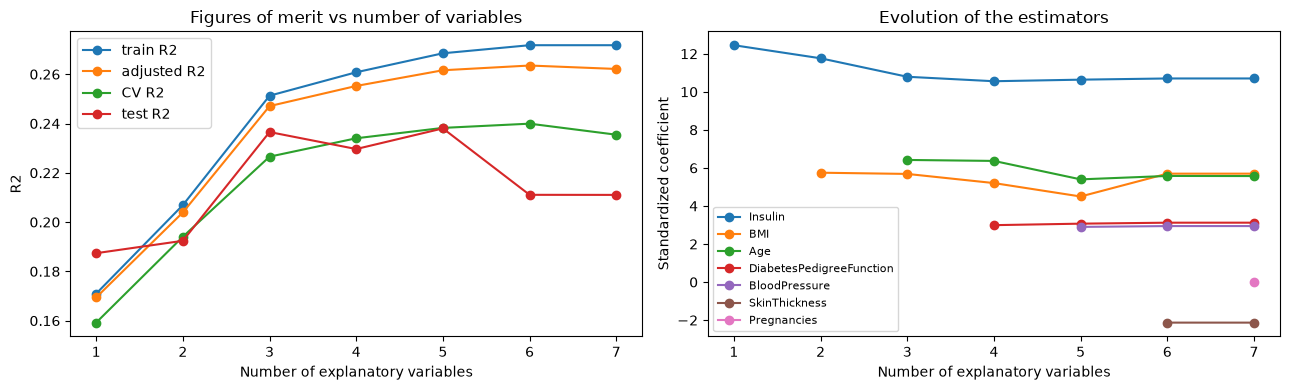

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
nvars_table[['train R2', 'adjusted R2', 'CV R2', 'test R2']].plot(marker='o', ax=axes[0])
axes[0].set_xlabel('Number of explanatory variables'); axes[0].set_ylabel('R2'); axes[0].set_title('Figures of merit vs number of variables')
pd.DataFrame(coef_evolution).T[ordered_features].plot(marker='o', ax=axes[1])
axes[1].set_xlabel('Number of explanatory variables'); axes[1].set_ylabel('Standardized coefficient'); axes[1].set_title('Evolution of the estimators')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [20]:
# Correlation of each feature with Glucose (training set) - a simple filter criterion
corr_with_glucose = pd.concat([X_train, Y_train], axis=1).corr()['Glucose'].drop('Glucose').sort_values(key=abs, ascending=False)
corr_with_glucose.round(3)

Insulin                     0.413
Age                         0.273
BMI                         0.238
BloodPressure               0.213
DiabetesPedigreeFunction    0.171
Pregnancies                 0.138
SkinThickness               0.131
Name: Glucose, dtype: float64

In [21]:
# You can explore results when: (1) normalizing data; (2) discarding some features based on their coefficients; (3) using other approaches such as stats
# (2) Discard the features with the smallest |coefficient|: Pregnancies and SkinThickness
reduced_features = [f for f in X.columns if f not in ['Pregnancies', 'SkinThickness']]
print("Reduced model features:", reduced_features)
_ = evaluate("Multiple LR Normalized - 5 features", make_pipeline(StandardScaler(), LinearRegression()),
             X_train[reduced_features], X_test[reduced_features])

Reduced model features: ['BloodPressure', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Multiple LR Normalized - 5 features
  CV (validation): R2 = 0.2382 ± 0.0513 | RMSE = 26.11
  Test:            R2 = 0.2380 | MAE = 21.90 | MSE = 737.21 | RMSE = 27.15


# Use statsmodels and compare the results

In [24]:
import statsmodels.api as sm
# statsmodels does not add the intercept automatically -> add_constant
X_train_sm = sm.add_constant(X_train_std)
mod = sm.OLS(Y_train, X_train_sm)
res = mod.fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                Glucose   R-squared:                       0.272
Model:                            OLS   Adj. R-squared:                  0.262
Method:                 Least Squares   F-statistic:                     28.20
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           5.11e-33
Time:                        11:55:10   Log-Likelihood:                -2505.2
No. Observations:                 537   AIC:                             5026.
Df Residuals:                     529   BIC:                             5061.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

In [25]:
# Same coefficients as sklearn?
comparison = pd.DataFrame({'sklearn': np.r_[mlr.intercept_, mlr.coef_], 'statsmodels': res.params.values,
                           'p-value': res.pvalues.values}, index=['const'] + list(X.columns))
print("Max difference between coefficients:", np.abs(comparison['sklearn'] - comparison['statsmodels']).max())
comparison.round(4)

Max difference between coefficients: 4.263256414560601e-14


,sklearn,statsmodels,p-value
const,121.9822,121.9822,0.0000
Pregnancies,0.0111,0.0111,0.9934
BloodPressure,2.9436,2.9436,0.0167
SkinThickness,-2.1315,-2.1315,0.1236
Insulin,10.7020,10.7020,0.0000
BMI,5.6985,5.6985,0.0001
DiabetesPedigreeFunction,3.1217,3.1217,0.0064
Age,5.5722,5.5722,0.0001


In [26]:
# Backward elimination using p-values: remove the least significant variable while p-value > 0.05
feats_be = list(X.columns)
while True:
    r = sm.OLS(Y_train, sm.add_constant(X_train_std[feats_be])).fit()
    pvals = r.pvalues.drop('const')
    if pvals.max() <= 0.05:
        break
    print(f"Removing {pvals.idxmax():25s} (p-value = {pvals.max():.3f})")
    feats_be.remove(pvals.idxmax())
print("\nSelected features:", feats_be)
print(f"Adjusted R2: all features = {res.rsquared_adj:.4f} | selected = {r.rsquared_adj:.4f}")
_ = evaluate("Multiple LR Normalized - backward elimination", make_pipeline(StandardScaler(), LinearRegression()),
             X_train[feats_be], X_test[feats_be])

Removing Pregnancies               (p-value = 0.993)
Removing SkinThickness             (p-value = 0.123)

Selected features: ['BloodPressure', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Adjusted R2: all features = 0.2621 | selected = 0.2616
Multiple LR Normalized - backward elimination
  CV (validation): R2 = 0.2382 ± 0.0513 | RMSE = 26.11
  Test:            R2 = 0.2380 | MAE = 21.90 | MSE = 737.21 | RMSE = 27.15


**Results with statsmodels.** `sm.OLS` gives **exactly the same coefficients** as scikit-learn (both solve the same least-squares problem) and the same training R² (0.272), but it also provides inference: standard errors, t-statistics, **p-values** and confidence intervals for each coefficient, the adjusted R² and the F-test of the global model (p ≈ 0, the model as a whole is significant). Scikit-learn is oriented to prediction, statsmodels to statistical inference.

**a) Effect of the number of explanatory variables** (table and plots above):
* **Estimators:** the coefficients change when new variables are added, because the features are correlated with each other. For example, the coefficient of Insulin decreases as BMI and Age enter the model (part of the effect it was capturing is now attributed to them), and SkinThickness takes a negative value when it enters after BMI. In a multiple regression each coefficient is an effect *conditional on the other variables*, so it depends on which variables are in the model.
* **Correlation coefficient:** the training R² (and the multiple correlation coefficient R = √R², the correlation between $y$ and $\hat y$) **always increases** (or stays the same) when a variable is added, even if it is useless (Pregnancies adds +0.0000). That is why the training R² cannot be used to choose variables.
* **Figures of merit:** the **adjusted R²** penalises the number of variables: it grows while the new variables are useful and **decreases** when Pregnancies is added. The **CV R²** and **test R²** improve a lot with the first 3 variables (Insulin, BMI, Age: test R² 0.19 → 0.24), then only marginally with DiabetesPedigreeFunction and BloodPressure, and the test R² even **drops** (0.238 → 0.211) when SkinThickness and Pregnancies are added. More variables ≠ better generalization.

**b) Most relevant features.** Process followed: (1) simple regressions with each feature (CV R²); (2) correlation of each feature with glucose; (3) standardized coefficients of the multiple model (comparable magnitudes); (4) forward addition of variables evaluating CV/test performance; (5) p-values of the OLS coefficients and backward elimination (remove the variable with highest p-value while p > 0.05). All criteria agree:
* **Most relevant: Insulin** (largest coefficient, p < 0.001, best single predictor), then **BMI** and **Age** (p < 0.001).
* **Relevant but weaker:** DiabetesPedigreeFunction (p ≈ 0.006) and BloodPressure (p ≈ 0.017).
* **Not relevant** in the multiple model: **SkinThickness** (p ≈ 0.12, redundant with BMI) and **Pregnancies** (p ≈ 0.99, redundant with Age). Backward elimination removes exactly these two, and the 5-feature model has the same (even slightly better) validation/test performance with fewer parameters.

Even so, all models explain only ~21–27 % of the variance of glucose: the available variables are weak predictors of glucose, which is mostly determined by factors not in the dataset.

## 5. Non-linear regression

Many of the relationships between variables we study are non-linear. As we have seen in theory, we can highlight the functions logarithmic, inverse, quadratic, cubic, power, exponential, etc.

a) Include which non-linear functions best fit the available data.

b) Indicate whether the performance obtained in the test set changes after normalizing the variables.

In [27]:
# a) Fit the classical non-linear functions with each of the most relevant single features
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures
from sklearn.compose import TransformedTargetRegressor

def nonlinear_models():
    return {
        'linear       y = a + b x':     make_pipeline(LinearRegression()),
        'logarithmic  y = a + b ln(x)': make_pipeline(FunctionTransformer(np.log), LinearRegression()),
        'inverse      y = a + b / x':   make_pipeline(FunctionTransformer(lambda x: 1 / x), LinearRegression()),
        'quadratic    y = a + b x + c x^2': make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression()),
        'cubic        y = a + b x + c x^2 + d x^3': make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()),
        # power: ln y = ln a + b ln x  ->  y = a x^b
        'power        y = a x^b':       TransformedTargetRegressor(make_pipeline(FunctionTransformer(np.log), LinearRegression()), func=np.log, inverse_func=np.exp),
        # exponential: ln y = ln a + b x  ->  y = a e^(bx)
        'exponential  y = a e^(b x)':   TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp),
    }

rows = []
for feat in ['Insulin', 'Age', 'BMI']:    # the 3 most relevant variables (all strictly positive -> log/inverse are defined)
    for name, model in nonlinear_models().items():
        cv_r2 = cross_val_score(model, X_train[[feat]], Y_train, cv=kfold, scoring='r2').mean()
        model.fit(X_train[[feat]], Y_train)
        rows.append({'feature': feat, 'function': name, 'CV R2': cv_r2,
                     'test R2': metrics.r2_score(Y_test, model.predict(X_test[[feat]]))})
nl_table = pd.DataFrame(rows).set_index(['feature', 'function'])
nl_table.round(4)

CV R2  test R2
feature function                                                 
Insulin linear       y = a + b x                  0.1592   0.1874
        logarithmic  y = a + b ln(x)              0.1451   0.2149
        inverse      y = a + b / x                0.0310   0.1259
        quadratic    y = a + b x + c x^2          0.1663   0.2160
        cubic        y = a + b x + c x^2 + d x^3  0.1649   0.2201
        power        y = a x^b                    0.1474   0.2116
        exponential  y = a e^(b x)                0.1253   0.1627
Age     linear       y = a + b x                  0.0513   0.0619
        logarithmic  y = a + b ln(x)              0.0549   0.0671
        inverse      y = a + b / x                0.0548   0.0698
        quadratic    y = a + b x + c x^2          0.0485   0.0664
        cubic        y = a + b x + c x^2 + d x^3  0.0450   0.0647
        power        y = a x^b                    0.0418   0.0643
        exponential  y = a e^(b x)                0.0368   0.0587
BMI     linear       y = a + b x                  0.0434   0.0450
        logarithmic  y = a + b ln(x)              0.0502   0.0402
        inverse      y = a + b / x                0.0548   0.0338
        quadratic    y = a + b x + c x^2          0.0400   0.0282
        cubic        y = a + b x + c x^2 + d x^3  0.0414   0.0207
        power        y = a x^b                    0.0365   0.0418
        exponential  y = a e^(b x)                0.0290   0.0448

In [28]:
# Best function per feature according to cross-validation
nl_table.reset_index().loc[nl_table.reset_index().groupby('feature')['CV R2'].idxmax()].set_index('feature').round(4)

,function,CV R2,test R2
feature,,,
Age,logarithmic y = a + b ln(x),0.0549,0.0671
BMI,inverse y = a + b / x,0.0548,0.0338
Insulin,quadratic y = a + b x + c x^2,0.1663,0.2160


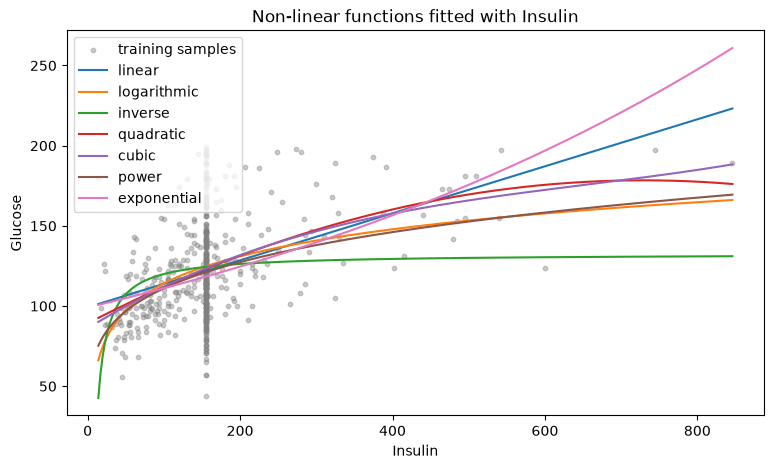

In [29]:
# Visualize the fitted curves for Insulin
xx = pd.DataFrame({'Insulin': np.linspace(X_train.Insulin.min(), X_train.Insulin.max(), 300)})
plt.figure(figsize=(9, 5))
plt.scatter(X_train['Insulin'], Y_train, s=10, alpha=0.4, color='grey', label='training samples')
for name, model in nonlinear_models().items():
    model.fit(X_train[['Insulin']], Y_train)
    plt.plot(xx['Insulin'], model.predict(xx), label=name.split()[0])
plt.xlabel('Insulin'); plt.ylabel('Glucose'); plt.legend(); plt.title('Non-linear functions fitted with Insulin')
plt.show()

**a) Which non-linear functions fit best.** We judge mainly by the **CV R²** (validation), using the test R² only as a confirmation.
* **Insulin** (the most informative variable): the relationship is **concave** — glucose rises with insulin and then flattens. The **quadratic** function is the best (CV R² 0.166, test R² 0.216), closely followed by the **cubic** (0.165 / 0.220); both improve on the straight line (0.159 / 0.187). The **logarithmic** and **power** functions have the right concave shape and do well on the test set (≈0.21) but slightly worse than the line in CV, so their gain is not robust. **Inverse** and **exponential** are clearly the worst (the exponential is convex, the opposite curvature). Note that the fitted quadratic reaches its maximum at Insulin ≈ 730 and then bends down, which is not physiologically plausible for the few extreme patients: polynomials must not be used to extrapolate.
* **Age** and **BMI**: all functions give practically the same, very low R² (0.03–0.07); the "best" ones (logarithmic for Age, inverse for BMI) win by less than 0.01, which is within the variability between folds, and for BMI the CV winner is worse on test. Their relationship with glucose is weak and essentially linear, so a non-linear function does not help.

**Conclusion:** the only useful non-linearity is a mild concave effect of Insulin, best captured by a **quadratic** (or log) term; the gain is small (≈ +0.01–0.03 R²).

In [30]:
# Non-linear regression with a defined degree (polynomial with ALL the features)
# (1) poly_reg = PolynomialFeatures(degree=4) # We can change the degree
# (2) Use fit_transform and transform and then LinearRegression()
# (3) Print the shape of the transformed features
poly_reg = PolynomialFeatures(degree=4)
X_train_poly = poly_reg.fit_transform(X_train_std)
X_test_poly = poly_reg.transform(X_test_std)
print(X_train_std.shape)
print(X_train_poly.shape)
print(Y_train.shape)
print(X_test_poly.shape)

lin_poly = LinearRegression().fit(X_train_poly, Y_train)
print("\nDegree 4 -> train R2:", round(lin_poly.score(X_train_poly, Y_train), 4))
r2, mae, mse, rmse = regression_metrics(Y_test, lin_poly.predict(X_test_poly))
print(f"Degree 4 -> test:  R2 = {r2:.4f} | MAE = {mae:.2f} | MSE = {mse:.2f} | RMSE = {rmse:.2f}")

(537, 7)
(537, 330)
(537,)
(231, 330)

Degree 4 -> train R2: 0.7284
Degree 4 -> test:  R2 = -84.7576 | MAE = 89.09 | MSE = 82968.78 | RMSE = 288.04


With 7 features, a degree-4 polynomial generates **330 terms** (all monomials up to degree 4, including the bias) to be fitted with only 537 patients. The model fits the training set much better (train R² 0.73 vs 0.27 for the linear model) but the test R² is strongly **negative** (−84.8, RMSE 288 mg/dl): its predictions are worse than always predicting the mean. A textbook case of **overfitting**.

,n terms,train RMSE,validation RMSE,validation R2
degree,,,,
1,8,25.642,26.160,0.235
2,36,24.460,27.443,0.162
3,120,21.201,68.522,-7.295
4,330,11.959,2515.822,-11123.427


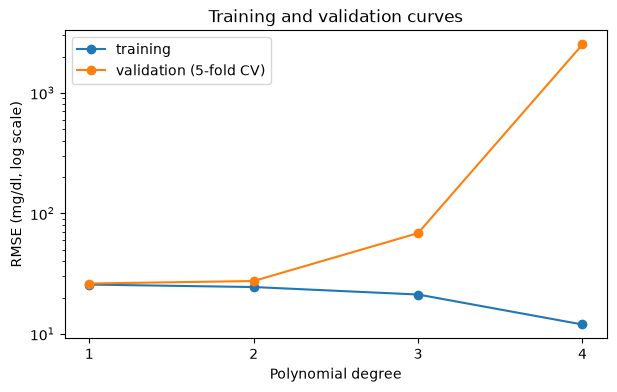

Best degree according to cross-validation: 1


In [31]:
# Use cross validation for finding the degree, train and predict with the best degree. Compute R2, MAE, MSE, RMSE.
# IMPORTANT: plot the train and the validations curve and analyze them.
from sklearn.model_selection import validation_curve
degrees = [1, 2, 3, 4]
poly_pipe = make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression())
train_scores, val_scores = validation_curve(poly_pipe, X_train, Y_train, param_name='polynomialfeatures__degree',
                                            param_range=degrees, cv=kfold, scoring='neg_root_mean_squared_error')
train_rmse, val_rmse = -train_scores.mean(axis=1), -val_scores.mean(axis=1)
_, val_r2 = validation_curve(poly_pipe, X_train, Y_train, param_name='polynomialfeatures__degree',
                             param_range=degrees, cv=kfold, scoring='r2')
curve = pd.DataFrame({'n terms': [PolynomialFeatures(d).fit(X_train).n_output_features_ for d in degrees],
                      'train RMSE': train_rmse, 'validation RMSE': val_rmse, 'validation R2': val_r2.mean(axis=1)}, index=degrees)
curve.index.name = 'degree'
display(curve.round(3))

plt.figure(figsize=(7, 4))
plt.plot(degrees, train_rmse, 'o-', label='training')
plt.plot(degrees, val_rmse, 'o-', label='validation (5-fold CV)')
plt.yscale('log'); plt.xticks(degrees)
plt.xlabel('Polynomial degree'); plt.ylabel('RMSE (mg/dl, log scale)'); plt.title('Training and validation curves')
plt.legend(); plt.show()

best_degree = int(curve['validation RMSE'].idxmin())
print("Best degree according to cross-validation:", best_degree)

**Analysis of the training/validation curves.** As the degree increases, the **training error decreases** monotonically (more flexible model, more terms: 8 → 36 → 120 → 330), but the **validation error increases**: slightly for degree 2 and explosively for degrees 3 and 4 (RMSE of hundreds or thousands of mg/dl on some folds, because the model takes absurd values outside the training points). The growing gap between the two curves is the signature of **overfitting**. The minimum validation error is obtained for **degree 1**, i.e. the plain multiple linear regression: with these data and this sample size, adding polynomial terms does not pay off. The best "really non-linear" polynomial is degree 2; we evaluate it below to include it in the comparison.

In [32]:
# Train with the best degree and evaluate on the test set
_ = evaluate(f"Polynomial degree {best_degree} Normalized (best CV degree)",
             make_pipeline(StandardScaler(), PolynomialFeatures(best_degree), LinearRegression()), X_train, X_test)
# Best non-linear option (degree 2)
_ = evaluate("Non-LR Normalized (polynomial degree 2)",
             make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression()), X_train, X_test)

Polynomial degree 1 Normalized (best CV degree)
  CV (validation): R2 = 0.2355 ± 0.0461 | RMSE = 26.16
  Test:            R2 = 0.2110 | MAE = 22.13 | MSE = 763.31 | RMSE = 27.63
Non-LR Normalized (polynomial degree 2)
  CV (validation): R2 = 0.1621 ± 0.0604 | RMSE = 27.44
  Test:            R2 = 0.1491 | MAE = 22.79 | MSE = 823.19 | RMSE = 28.69


In [33]:
# b) Does the performance change after normalizing? Same polynomial models with and without StandardScaler
rows = []
for d in [1, 2, 3, 4]:
    for norm in [False, True]:
        steps = ([StandardScaler()] if norm else []) + [PolynomialFeatures(d), LinearRegression()]
        m = make_pipeline(*steps).fit(X_train, Y_train)
        Xp = make_pipeline(*steps[:-1]).fit(X_train).transform(X_train)
        rows.append({'degree': d, 'normalized': norm, 'train R2': m.score(X_train, Y_train),
                     'test R2': metrics.r2_score(Y_test, m.predict(X_test)),
                     'condition number of X': np.linalg.cond(Xp)})
norm_table = pd.DataFrame(rows).set_index(['degree', 'normalized'])
pd.options.display.float_format = '{:.4g}'.format
display(norm_table)
pd.options.display.float_format = None

train R2  test R2  condition number of X
degree normalized                                          
1      False         0.2718    0.211                   1382
       True          0.2718    0.211                    2.3
2      False         0.3178   0.1723              2.513e+06
       True          0.3275   0.1491                  14.35
3      False         0.4024   -3.068              1.024e+10
       True          0.4655   -4.392                  311.7
4      False         0.3714  -0.1637              1.009e+14
       True          0.7284   -84.76              2.221e+04

**b) Effect of normalization on the non-linear models.**
* For the **single-feature transformations** (log, inverse, power, exponential) normalization is not applicable/needed: they need the original positive values (ln and 1/x of a standardized variable would be undefined for negative values).
* For **degree 1** the results with and without normalization are identical (as in Section 3).
* For **polynomials of degree ≥ 2 the results do change.** In theory they should not: a polynomial of the standardized variables spans exactly the same functions as a polynomial of the original variables, so ordinary least squares should give the same predictions. In practice, without normalization the polynomial terms have wildly different scales (Insulin⁴ ≈ 10¹¹ vs DiabetesPedigreeFunction⁴ < 40) and the design matrix is extremely **ill-conditioned** (condition number up to ~10¹⁴ vs ~10⁴ normalized, see table): the least-squares solver loses precision, so it does not even reach the true minimum of the training error (see the lower training R² without normalization; we checked that an exact least-squares solution on rescaled columns gives exactly the normalized result, 0.3275 for degree 2). With normalization the problem is much better conditioned and the solver finds the true least-squares solution. Here the non-normalized degree-2/4 models get a less bad test R² *by accident* (the numerical truncation acts like a crude regularization), but that is not a reliable property. Conclusion: **always normalize before generating polynomial features**, and if a flexible model is needed, control its complexity explicitly with CV and regularization (next section), not with numerical errors.

## 6. Linear regression with regularization

a) Indicate whether the performance obtained in the test set changes when changing the regularization considered.

b) Justify which features are more relevant for these models

In [34]:
# Use a Ridge Regression
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
ridge = Ridge()

# Values for alpha
parameters = {"alpha": [1e-15, 1e-10, 1e-8, 1e-4, 1e-3, 1e-2, 1, 5, 10, 20, 30]}

# Use grid search for ridge regression and then train and predict and provide R2, MAE, MSE, RMSE values
# Regularization is NOT scale-invariant -> features must be standardized (we use the normalized sets)
ridge_regressor = GridSearchCV(ridge, parameters, scoring='neg_mean_squared_error', cv=kfold)
ridge_regressor.fit(X_train_std, Y_train)

# Which is the best value of the regularization parameter?
print("Best alpha:", ridge_regressor.best_params_, "| best CV MSE:", round(-ridge_regressor.best_score_, 2))
y_pred_ridge = ridge_regressor.predict(X_test_std)
r2, mae, mse, rmse = regression_metrics(Y_test, y_pred_ridge)
print(f"Test: R2 = {r2:.4f} | MAE = {mae:.2f} | MSE = {mse:.2f} | RMSE = {rmse:.2f}")
print("Ridge coefficients:", dict(zip(X.columns, ridge_regressor.best_estimator_.coef_.round(3))))

best_alpha_ridge = ridge_regressor.best_params_['alpha']
_ = evaluate(f"Ridge (alpha={best_alpha_ridge})", make_pipeline(StandardScaler(), Ridge(alpha=best_alpha_ridge)), X_train, X_test, verbose=False)

Best alpha: {'alpha': 30} | best CV MSE: 683.52
Test: R2 = 0.2172 | MAE = 22.12 | MSE = 757.35 | RMSE = 27.52
Ridge coefficients: {'Pregnancies': np.float64(0.19), 'BloodPressure': np.float64(2.917), 'SkinThickness': np.float64(-1.67), 'Insulin': np.float64(10.188), 'BMI': np.float64(5.225), 'DiabetesPedigreeFunction': np.float64(3.042), 'Age': np.float64(5.234)}


Best alpha in the extended grid: 31.62


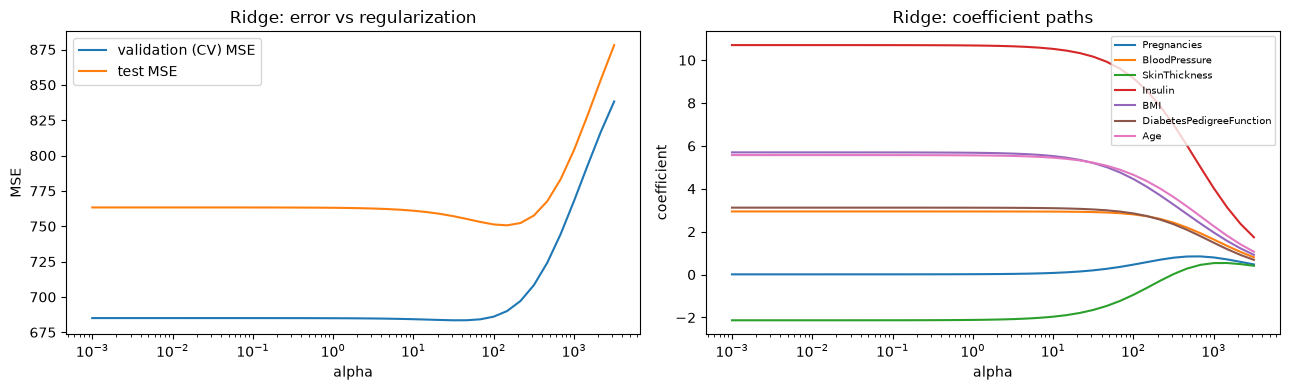

Ridge (alpha=31.6, extended grid)
  CV (validation): R2 = 0.2368 ± 0.0481 | RMSE = 26.13
  Test:            R2 = 0.2174 | MAE = 22.12 | MSE = 757.10 | RMSE = 27.52


In [35]:
# The best alpha is the largest value of the grid -> extend the grid to check that we found the optimum
alphas = np.logspace(-3, 3.5, 40)
ridge_curve = GridSearchCV(Ridge(), {'alpha': alphas}, scoring='neg_mean_squared_error', cv=kfold).fit(X_train_std, Y_train)
cv_mse = -ridge_curve.cv_results_['mean_test_score']
test_mse = [metrics.mean_squared_error(Y_test, Ridge(alpha=a).fit(X_train_std, Y_train).predict(X_test_std)) for a in alphas]
ridge_coefs = np.array([Ridge(alpha=a).fit(X_train_std, Y_train).coef_ for a in alphas])
print("Best alpha in the extended grid:", round(ridge_curve.best_params_['alpha'], 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].semilogx(alphas, cv_mse, label='validation (CV) MSE'); axes[0].semilogx(alphas, test_mse, label='test MSE')
axes[0].set_xlabel('alpha'); axes[0].set_ylabel('MSE'); axes[0].set_title('Ridge: error vs regularization'); axes[0].legend()
for j, f in enumerate(X.columns):
    axes[1].semilogx(alphas, ridge_coefs[:, j], label=f)
axes[1].set_xlabel('alpha'); axes[1].set_ylabel('coefficient'); axes[1].set_title('Ridge: coefficient paths'); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

best_alpha_ridge_ext = ridge_curve.best_params_['alpha']
_ = evaluate(f"Ridge (alpha={best_alpha_ridge_ext:.1f}, extended grid)", make_pipeline(StandardScaler(), Ridge(alpha=best_alpha_ridge_ext)), X_train, X_test)

In [36]:
# Use a Lasso Regression
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso
lasso_regression = Lasso(max_iter=100000)

# Values for alpha
parameters = {"alpha": [1e-4, 1e-2, 1, 5, 10, 20]}

lasso_regressor = GridSearchCV(lasso_regression, parameters, scoring='neg_mean_squared_error', cv=kfold)
lasso_regressor.fit(X_train_std, Y_train)

# Which is the best value of the regularization parameter?
print("Best alpha:", lasso_regressor.best_params_, "| best CV MSE:", round(-lasso_regressor.best_score_, 2))
y_pred_lasso = lasso_regressor.predict(X_test_std)
r2, mae, mse, rmse = regression_metrics(Y_test, y_pred_lasso)
print(f"Test: R2 = {r2:.4f} | MAE = {mae:.2f} | MSE = {mse:.2f} | RMSE = {rmse:.2f}")

best_alpha_lasso = lasso_regressor.best_params_['alpha']
_ = evaluate(f"Lasso (alpha={best_alpha_lasso})", make_pipeline(StandardScaler(), Lasso(alpha=best_alpha_lasso, max_iter=100000)), X_train, X_test, verbose=False)

Best alpha: {'alpha': 1} | best CV MSE: 684.57
Test: R2 = 0.2400 | MAE = 21.99 | MSE = 735.28 | RMSE = 27.12


In [37]:
# Coefficients and performance for every alpha of the grid (shows how Lasso sets coefficients to 0)
lasso_rows, lasso_coefs = [], {}
for a in parameters['alpha']:
    m = Lasso(alpha=a, max_iter=100000).fit(X_train_std, Y_train)
    lasso_coefs[a] = pd.Series(m.coef_, index=X.columns)
    lasso_rows.append({'alpha': a, 'CV MSE': -lasso_regressor.cv_results_['mean_test_score'][parameters['alpha'].index(a)],
                       'test R2': metrics.r2_score(Y_test, m.predict(X_test_std)), 'n non-zero coefs': int((m.coef_ != 0).sum())})
display(pd.DataFrame(lasso_rows).set_index('alpha').round(4))
print("Lasso coefficients for each alpha:")
pd.DataFrame(lasso_coefs).round(3)

,CV MSE,test R2,n non-zero coefs
alpha,,,
0.0001,685.0563,0.2110,7
0.0100,684.9676,0.2115,7
1.0000,684.5733,0.2400,5
5.0000,757.4332,0.1816,4
10.0000,863.4781,0.0614,1
20.0000,909.0825,-0.0010,0


Lasso coefficients for each alpha:


,0.0001,0.0100,1.0000,5.0000,10.0000,20.0000
Pregnancies,0.011,0.003,0.000,0.000,0.00,0.0
BloodPressure,2.944,2.937,2.324,0.048,0.00,0.0
SkinThickness,-2.131,-2.105,-0.000,0.000,0.00,0.0
Insulin,10.702,10.694,9.920,6.977,2.45,0.0
BMI,5.698,5.677,3.878,1.250,0.00,0.0
DiabetesPedigreeFunction,3.122,3.113,2.283,0.000,0.00,0.0
Age,5.572,5.568,4.745,2.109,0.00,0.0


In [38]:
# Regularization is most useful when the model has many parameters: Ridge and Lasso on the degree-2 polynomial (35 terms)
poly2_ridge = GridSearchCV(make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), Ridge()),
                           {'ridge__alpha': [1e-2, 1, 10, 30, 100, 200, 500, 1000]}, scoring='neg_mean_squared_error', cv=kfold).fit(X_train, Y_train)
print("Polynomial deg 2 + Ridge, best alpha:", poly2_ridge.best_params_)
_ = evaluate("Ridge on polynomial degree 2", poly2_ridge.best_estimator_, X_train, X_test)

poly2_lasso = GridSearchCV(make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), Lasso(max_iter=100000)),
                           {'lasso__alpha': [1e-2, 0.1, 0.5, 1, 2, 5]}, scoring='neg_mean_squared_error', cv=kfold).fit(X_train, Y_train)
print("Polynomial deg 2 + Lasso, best alpha:", poly2_lasso.best_params_)
_ = evaluate("Lasso on polynomial degree 2", poly2_lasso.best_estimator_, X_train, X_test)

names_p2 = poly2_lasso.best_estimator_.named_steps['polynomialfeatures'].get_feature_names_out(X.columns)
coef_p2 = pd.Series(poly2_lasso.best_estimator_.named_steps['lasso'].coef_, index=names_p2)
print(f"\nLasso keeps {(coef_p2 != 0).sum()} of {len(coef_p2)} polynomial terms. Largest ones:")
coef_p2[coef_p2 != 0].sort_values(key=abs, ascending=False).head(10).round(3)

Polynomial deg 2 + Ridge, best alpha: {'ridge__alpha': 200}
Ridge on polynomial degree 2
  CV (validation): R2 = 0.1946 ± 0.0354 | RMSE = 26.87
  Test:            R2 = 0.1710 | MAE = 22.79 | MSE = 802.00 | RMSE = 28.32
Polynomial deg 2 + Lasso, best alpha: {'lasso__alpha': 2}
Lasso on polynomial degree 2
  CV (validation): R2 = 0.2282 ± 0.0394 | RMSE = 26.29
  Test:            R2 = 0.2388 | MAE = 22.11 | MSE = 736.48 | RMSE = 27.14

Lasso keeps 6 of 36 polynomial terms. Largest ones:


Insulin                         9.261
Age                             4.183
BMI                             3.174
BloodPressure                   1.722
BMI DiabetesPedigreeFunction    1.168
DiabetesPedigreeFunction        1.099
dtype: float64

**a) Does the test performance change with the regularization?** Yes, and the plots/tables show the typical behaviour:
* With **very small α** (1e-15 … 1e-2) Ridge and Lasso are practically identical to ordinary least squares (same coefficients and R² ≈ 0.211 on test).
* With **moderate α** the coefficients shrink and the validation error decreases slightly: the best α by cross-validation are **α = 30 for Ridge** (the largest value of the proposed grid; extending the grid confirms the optimum is around α ≈ 32, after which the error grows again) and **α = 1 for Lasso**. Both improve a little on the test set (Ridge R² 0.217, Lasso R² 0.240 vs 0.211 for plain MLR).
* With **too large α** the model **underfits**: the coefficients are forced towards 0 and the error grows. In Lasso with α = 10 only Insulin survives and with α = 20 *all* coefficients are 0, so the model predicts the mean glucose for everyone (test R² ≈ 0).

The improvements for the 7-feature linear model are small because this model has few parameters (8) for 537 patients and was not overfitting much. Regularization makes a bigger difference with complex models: on the degree-2 polynomial (36 terms), which without regularization had test R² 0.149, **Lasso (α = 2)** keeps only 6 terms (essentially the linear terms of Insulin, Age, BMI, BloodPressure and DiabetesPedigreeFunction plus a BMI×DiabetesPedigreeFunction interaction) and goes up to test R² 0.239, almost the same as the linear Lasso; Ridge needs a very large α (200) and only reaches 0.171. The improvements are, in any case, of the same order as the variability between CV folds (± 0.04–0.05), so all regularized linear models perform essentially the same.

**b) Most relevant features.** With standardized inputs, the magnitude of the coefficients measures relevance. **Lasso** is especially informative because it performs **automatic feature selection**: as α grows, the least useful coefficients become exactly 0. The order in which they disappear gives a ranking: **Pregnancies** and **SkinThickness** are removed first (already at α = 1), then DiabetesPedigreeFunction (α = 5, where BloodPressure is also almost 0), then BMI and Age, and **Insulin** is the last to survive (α = 10). Ridge shrinks all coefficients but none becomes 0; its ranking (Insulin > BMI ≈ Age > DiabetesPedigreeFunction ≈ BloodPressure > SkinThickness > Pregnancies) is the same. This matches the conclusions of Section 4 (p-values, backward elimination): **Insulin, BMI and Age** are the most relevant, then DiabetesPedigreeFunction and BloodPressure, while Pregnancies and SkinThickness are redundant.

## 7. Comparison of the results obtained with the different models

Provide in a table the performance measures obtained both in the validation and test set by the different models designed.

In view of the results obtained, please answer, if possible, the following questions:

a) Justify whether the fact of normalizing the feature's values influence the results obtained.

b) Reasonably justify whether you would use a linear or non-linear parametric scheme. Indicate and justify the scheme that provides the best performance in the set of tests.

c) Indicate and justify which are the most relevant features as well as the procedure to identify them.

d) Indicate and justify whether the fact of making a single partition of the cases in the training and test sets can influence the results obtained. Starting from the original data, make a new partition of the cases in the training and test sets. Select one of the analyzed models (indicate the chosen models) and obtain again the figures of merit. Comment the obtained results.

In [40]:
# Table with the performance in validation (5-fold CV on the training set) and in the test set
results = pd.DataFrame()
results["Models"] = model_names
results["R2 validation (CV)"] = cv_r2_results
results["RMSE validation (CV)"] = cv_rmse_results
results["R2 in the test set"] = r2_results
results["MAE in the test set"] = mae_results
results["MSE in the test set"] = mse_results
results["RMSE in the test set"] = rmse_results
results.set_index("Models", inplace=True)
results.style.format('{:.4f}').highlight_max(subset=['R2 validation (CV)', 'R2 in the test set'], color='lightgreen') \
              .highlight_min(subset=['RMSE validation (CV)', 'MAE in the test set', 'MSE in the test set', 'RMSE in the test set'], color='lightgreen')

,R2 validation (CV),RMSE validation (CV),R2 in the test set,MAE in the test set,MSE in the test set,RMSE in the test set
Models,,,,,,
Linear Regression (LR) - Age,0.0513,29.1621,0.0619,25.0620,907.5610,30.1258
LR Normalized - Age,0.0513,29.1621,0.0619,25.0620,907.5610,30.1258
Multiple LR Normalized,0.2355,26.1602,0.2110,22.1292,763.3111,27.6281
Multiple LR Normalized - 5 features,0.2382,26.1052,0.2380,21.8993,737.2131,27.1517
Multiple LR Normalized - backward elimination,0.2382,26.1052,0.2380,21.8993,737.2131,27.1517
Polynomial degree 1 Normalized (best CV degree),0.2355,26.1602,0.2110,22.1292,763.3111,27.6281
Non-LR Normalized (polynomial degree 2),0.1621,27.4425,0.1491,22.7936,823.1912,28.6913
Ridge (alpha=30),0.2368,26.1346,0.2172,22.1225,757.3501,27.5200
"Ridge (alpha=31.6, extended grid)",0.2368,26.1343,0.2174,22.1230,757.1029,27.5155


,n,MAE,RMSE,mean residual (y - y_pred)
Non-diabetic (0),151,20.95,25.82,-8.24
Diabetic (1),80,24.36,30.75,10.73


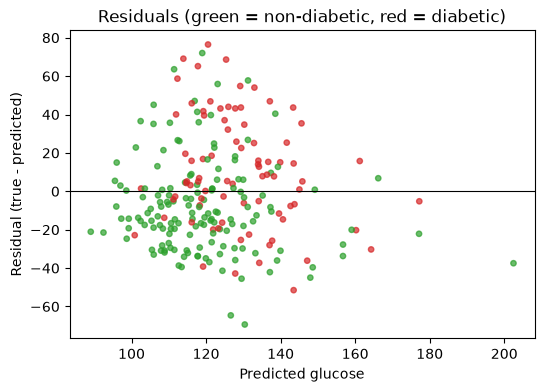

In [41]:
# Error by class (diabetic vs non-diabetic) for the multiple linear model: is the error homogeneous?
best_lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, Y_train)
residuals = Y_test - best_lin.predict(X_test)
outcome_test = data.loc[X_test.index, 'Outcome']
by_class = pd.DataFrame({'n': outcome_test.value_counts(),
                         'MAE': residuals.abs().groupby(outcome_test).mean(),
                         'RMSE': np.sqrt((residuals ** 2).groupby(outcome_test).mean()),
                         'mean residual (y - y_pred)': residuals.groupby(outcome_test).mean()})
by_class.index = ['Non-diabetic (0)', 'Diabetic (1)']
display(by_class.round(2))

plt.figure(figsize=(6, 4))
plt.scatter(best_lin.predict(X_test), residuals, c=outcome_test.map({0: 'tab:green', 1: 'tab:red'}), s=15, alpha=0.7)
plt.axhline(0, color='k', lw=0.8); plt.xlabel('Predicted glucose'); plt.ylabel('Residual (true - predicted)')
plt.title('Residuals (green = non-diabetic, red = diabetic)'); plt.show()

In [42]:
# d) New partition of the original data: same model (Multiple LR normalized), different random_state
for rs in [42, 7]:
    Xtr, Xte, ytr, yte = train_test_split(X, Y, test_size=0.3, random_state=rs)
    m = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
    r2, mae, mse, rmse = regression_metrics(yte, m.predict(Xte))
    cv = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), Xtr, ytr, cv=kfold, scoring='r2').mean()
    print(f"random_state={rs:3d}: CV R2 = {cv:.4f} | test R2 = {r2:.4f} | MAE = {mae:.2f} | MSE = {mse:.2f} | RMSE = {rmse:.2f}")
    print("               coefficients:", dict(zip(X.columns, m[-1].coef_.round(2))))

random_state= 42: CV R2 = 0.2355 | test R2 = 0.2110 | MAE = 22.13 | MSE = 763.31 | RMSE = 27.63
               coefficients: {'Pregnancies': np.float64(0.01), 'BloodPressure': np.float64(2.94), 'SkinThickness': np.float64(-2.13), 'Insulin': np.float64(10.7), 'BMI': np.float64(5.7), 'DiabetesPedigreeFunction': np.float64(3.12), 'Age': np.float64(5.57)}
random_state=  7: CV R2 = 0.2040 | test R2 = 0.2764 | MAE = 19.99 | MSE = 670.97 | RMSE = 25.90
               coefficients: {'Pregnancies': np.float64(-1.86), 'BloodPressure': np.float64(4.04), 'SkinThickness': np.float64(0.79), 'Insulin': np.float64(9.73), 'BMI': np.float64(3.99), 'DiabetesPedigreeFunction': np.float64(2.31), 'Age': np.float64(5.78)}


,Multiple LR,Lasso (alpha=1),Polynomial deg 2
mean,0.2302,0.2315,0.1699
std,0.0384,0.0351,0.0532
min,0.1374,0.1444,-0.0134
max,0.3125,0.3056,0.2693


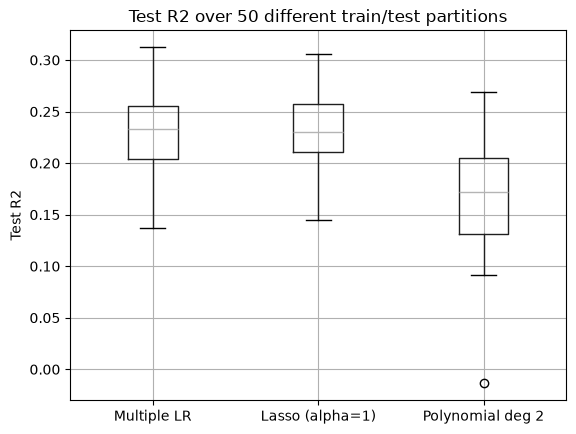

In [43]:
# To quantify the effect of the partition: repeat with 50 different partitions (MLR, Lasso alpha=1 and polynomial deg 2)
rep = {'Multiple LR': [], 'Lasso (alpha=1)': [], 'Polynomial deg 2': []}
for rs in range(50):
    Xtr, Xte, ytr, yte = train_test_split(X, Y, test_size=0.3, random_state=rs)
    for name, m in [('Multiple LR', make_pipeline(StandardScaler(), LinearRegression())),
                    ('Lasso (alpha=1)', make_pipeline(StandardScaler(), Lasso(alpha=1, max_iter=100000))),
                    ('Polynomial deg 2', make_pipeline(StandardScaler(), PolynomialFeatures(2), LinearRegression()))]:
        rep[name].append(metrics.r2_score(yte, m.fit(Xtr, ytr).predict(Xte)))
rep = pd.DataFrame(rep)
display(rep.describe().loc[['mean', 'std', 'min', 'max']].round(4))
rep.boxplot(); plt.ylabel('Test R2'); plt.title('Test R2 over 50 different train/test partitions'); plt.show()

**Conclusions**

**a) Influence of normalization.** For ordinary least squares (simple and multiple linear regression) normalization **does not change the predictions or the figures of merit** (identical R², MAE, MSE, RMSE); it only changes the scale of the coefficients, but it makes them **comparable**, which is necessary to interpret the relevance of each feature. It **does** influence: (1) **regularized models** (Ridge, Lasso), because the penalty $\alpha\sum w_j^2$ or $\alpha\sum|w_j|$ depends on the scale of each coefficient — without normalization the variables with small units would be penalised much more than those with large units; and (2) **polynomial models**, where without normalization the design matrix is numerically ill-conditioned and the solution is not reliable. Therefore normalizing (with the statistics of the training set only) is always good practice.

**b) Linear or non-linear scheme.** I would use a **linear scheme** (multiple linear regression, preferably regularized). Reasons: the cross-validation curve of the polynomial models has its minimum at **degree 1**; degree 2 is already worse in validation, and degrees 3–4 overfit dramatically; the only clear non-linearity is the concave effect of Insulin (which could be captured with a log transform of that single variable); and the linear model is simpler, more stable and interpretable. In the test set the best figures are obtained by **Lasso (α = 1) with the 7 linear features** (R² 0.240, RMSE 27.12), practically tied with Lasso on the degree-2 polynomial (0.239) and the 5-feature multiple linear regression (0.238), followed by Ridge (0.217) and the full multiple linear regression (0.211); the unregularized polynomial of degree 2 is worse (0.149) and degree 4 is useless (−84.8). However, these differences between linear models (≈0.01–0.03 in R²) are smaller than the variability caused by the partition (std ≈ 0.04, see d), and in CV all of them score ≈0.23–0.24; so the most reasonable choice is **Lasso (α = 1) on the 7 linear features**: it is among the best in validation and test, it removes irrelevant variables (Pregnancies, SkinThickness) and it is easy to interpret. Note also that all models are weak (they explain only ~20–25 % of the glucose variance, RMSE ≈ 27 mg/dl), and the per-class analysis shows that they **underestimate the glucose of diabetic patients** (positive mean residual for class 1, larger RMSE) and overestimate it in non-diabetic ones — the effect of the class imbalance discussed in Section 2c.

**c) Most relevant features and procedure.** **Insulin** is the most relevant feature, followed by **BMI** and **Age**; DiabetesPedigreeFunction and BloodPressure have a small but significant contribution, and **Pregnancies** and **SkinThickness** are not relevant once the others are present (they are redundant with Age and BMI, respectively). Procedure: (1) simple regressions and correlations of each feature with glucose; (2) magnitude of the **standardized coefficients** of the multiple model; (3) **p-values** of the OLS model (statsmodels) and **backward elimination**; (4) **forward addition** of variables checking CV/test performance; (5) **Lasso**, which sets the coefficients of irrelevant features to exactly zero as α increases. All methods give the same ranking.

**d) Influence of a single partition.** Yes: with only 768 patients, which patients fall in the test set (231) has a noticeable effect on the figures of merit. With a new partition (`random_state=7` instead of 42) the same model (multiple linear regression, normalized) gives test R² = 0.276 and RMSE = 25.9 instead of 0.211 and 27.6 — apparently much better, although its CV R² on the new training set is actually lower (0.204 vs 0.236): we simply got an "easier" test set. The coefficients also change: Insulin and Age remain the largest, but BloodPressure and BMI swap places and the small coefficients (Pregnancies, SkinThickness) even **change sign**, confirming they are not reliable/relevant. Repeating the experiment with 50 partitions, the test R² of the multiple linear regression varies between 0.14 and 0.31 (mean 0.23, std ≈ 0.04). This variability is larger than many of the differences between models in the comparison table, so a single partition is **not enough to decide which model is better**: conclusions should be based on cross-validation (as we did to choose hyper-parameters) or on **repeated partitions / repeated k-fold CV**, reporting mean ± std. Notice that, averaged over many partitions, the polynomial degree-2 model is clearly worse and more unstable than the linear models, confirming the conclusion of (b).